# 01 · Water shortage - Table 8

Section 3.2 of the paper: the hot stream flow rates increased by 20 % during the plant
lifetime (shell-side film coefficients follow a power law with exponent 0.6), but the cooling
water system was not modified. The existing network is **simulated** (fixed pipes, pump and
fully open valves) for the initial and the current conditions.

Two independent implementations are compared: a NumPy/SciPy simulator (hydraulic balance +
P-NTU coolers + Merkel tower) and the Pyomo model solved as a square NLP with IPOPT.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from coolingnet import paper_case
from coolingnet.optimization import SolverSettings
from coolingnet.reporting import paper_reference as REF
from coolingnet.reporting import tables as T
from coolingnet.simulation import simulate_design
from coolingnet.workflow import PaperPipeline, PipelineConfig

RESULTS_DIR = Path("../results")  # produced by `coolingnet run`; re-used by every notebook
FORCE_RESOLVE = False  # True: ignore cached results and solve again

case = paper_case()
factor = case.scenarios.hot_flow_increase_factor
pipeline = PaperPipeline(case, PipelineConfig(results_dir=RESULTS_DIR, force=FORCE_RESOLVE, solver=SolverSettings(name="nlpbb", time_limit_s=600)))

## NumPy/SciPy simulation of the existing design

In [2]:
sim_initial = simulate_design(case, hot_flow_factor=1.0)
sim_current = simulate_design(case, hot_flow_factor=factor)
rows = []
for tag in sim_initial.exchangers:
    rows.append(
        {
            "Heat exchanger": tag,
            "Design condition (C)": case.heat_exchanger(tag).hot_outlet_spec_C,
            "Initial condition (C)": sim_initial.exchangers[tag]["T_hot_out_C"],
            "Current condition (C)": sim_current.exchangers[tag]["T_hot_out_C"],
            "Current condition penalty (kUSD/y)": sim_current.exchangers[tag]["penalty_USD_y"] / 1e3,
            "Water flow (kg/s)": sim_current.exchangers[tag]["k_kg_s"],
        }
    )
table8_numpy = pd.DataFrame(rows).set_index("Heat exchanger")
display(table8_numpy.round(2))
print(f"tower: T_w,in = {sim_current.T_w_in_C:.2f} C, T_feed = {sim_current.T_w_feed_C:.2f} C; "
      f"operating cost = {sim_current.operating_cost_USD_y / 1e3:.2f} kUSD/y; total penalty = {sim_current.penalty_USD_y / 1e3:.2f} kUSD/y")

,Design condition (C),Initial condition (C),Current condition (C),Current condition penalty (kUSD/y),Water flow (kg/s)
Heat exchanger,,,,,
E-101,65.0,63.48,65.16,1.96,11.92
E-102,80.0,78.39,81.59,19.82,28.85
E-103,40.0,39.66,41.82,22.70,35.57
E-104,41.0,40.91,42.81,22.61,15.53
E-105,41.0,39.75,41.53,6.62,3.23


tower: T_w,in = 32.82 C, T_feed = 42.00 C; operating cost = 20.16 kUSD/y; total penalty = 73.71 kUSD/y


## Table 8 with the optimization model (Pyomo + IPOPT) and comparison with the paper

In [3]:
sims = pipeline.run_simulations()
table8 = T.table_heat_exchangers_performance(case, sims["initial"], sims["current"])
display(table8.round(2))
display(REF.compare(REF.TABLE8, table8.drop(index="Total")).round(2))
print("paper total penalty:", REF.TABLE8_TOTAL_PENALTY, "kUSD/y  |  this work:", round(table8.loc["Total", "Current condition penalty (kUSD/y)"], 2))

,Design condition (C),Initial condition (C),Current condition (C),Current condition penalty (kUSD/y)
E-101,65.0,63.48,65.16,1.96
E-102,80.0,78.39,81.59,19.82
E-103,40.0,39.66,41.82,22.70
E-104,41.0,40.91,42.81,22.61
E-105,41.0,39.75,41.53,6.62
Total,NaN,NaN,NaN,73.71


,Design condition (C) [paper],Design condition (C) [this work],Initial condition (C) [paper],Initial condition (C) [this work],Current condition (C) [paper],Current condition (C) [this work],Current condition penalty (kUSD/y) [paper],Current condition penalty (kUSD/y) [this work]
Heat exchanger,,,,,,,,
E-101,65.0,65.0,63.48,63.48,65.16,65.16,1.96,1.96
E-102,80.0,80.0,78.39,78.39,81.59,81.59,19.82,19.82
E-103,40.0,40.0,39.66,39.66,41.82,41.82,22.70,22.70
E-104,41.0,41.0,40.91,40.91,42.81,42.81,22.61,22.61
E-105,41.0,41.0,39.75,39.75,41.53,41.53,6.62,6.62


paper total penalty: 73.71 kUSD/y  |  this work: 73.71


The outlet temperatures at the initial operation are lower than the design values (excess area),
while the current condition violates every set-point. Both implementations agree with the paper
to the published precision.

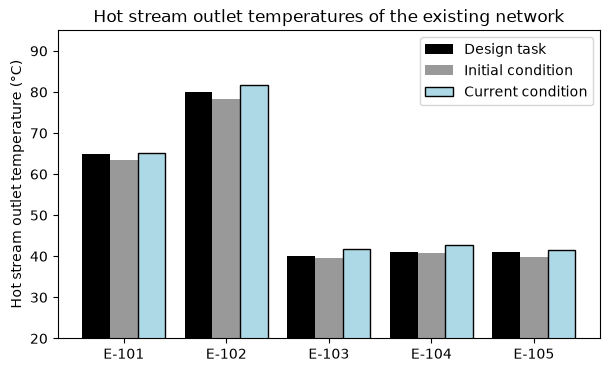

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
tags = list(table8.index[:-1])
x = range(len(tags))
w = 0.27
ax.bar([i - w for i in x], table8.loc[tags, "Design condition (C)"], w, color="black", label="Design task")
ax.bar(list(x), table8.loc[tags, "Initial condition (C)"], w, color="0.6", label="Initial condition")
ax.bar([i + w for i in x], table8.loc[tags, "Current condition (C)"], w, color="lightblue", edgecolor="black", label="Current condition")
ax.set_xticks(list(x))
ax.set_xticklabels(tags)
ax.set_ylabel("Hot stream outlet temperature (°C)")
ax.set_ylim(20, 95)
ax.legend()
ax.set_title("Hot stream outlet temperatures of the existing network")
plt.show()

## A note on the Merkel quadrature points

The paper text lists the abscissae $\alpha_m$ = (0.1, 0.4, 0.6, 0.9) for the 4-point
Chebyshev integration of the Merkel integral, but the GAMS code that produced the published
results used (0.1, 0.4, 0.6, **0.7**). The configuration keeps the code value so that the
tables match; the cell below shows the (small) effect of the textbook value.

In [5]:
alt_tower = case.cooling_tower.model_copy(update={"quadrature_points": [0.1, 0.4, 0.6, 0.9]})
sim_alt = simulate_design(case.with_updates(cooling_tower=alt_tower), hot_flow_factor=1.0)
pd.DataFrame(
    {
        "alpha4 = 0.7 (code, paper tables)": [sim_initial.T_w_in_C, sim_initial.T_w_feed_C] + [v["T_hot_out_C"] for v in sim_initial.exchangers.values()],
        "alpha4 = 0.9 (paper text)": [sim_alt.T_w_in_C, sim_alt.T_w_feed_C] + [v["T_hot_out_C"] for v in sim_alt.exchangers.values()],
    },
    index=["T_w,in (C)", "T_feed (C)"] + [f"T_hot,out {t} (C)" for t in sim_initial.exchangers],
).round(3)

,"alpha4 = 0.7 (code, paper tables)",alpha4 = 0.9 (paper text)
"T_w,in (C)",32.202,32.125
T_feed (C),40.422,40.357
"T_hot,out E-101 (C)",63.480,63.453
"T_hot,out E-102 (C)",78.387,78.351
"T_hot,out E-103 (C)",39.661,39.596
"T_hot,out E-104 (C)",40.905,40.847
"T_hot,out E-105 (C)",39.748,39.686
